# TAHAP 4: OPTIMASI & KOMPARASI MENDALAM K-MEANS VS HIERARCHICAL CLUSTERING
## Studi Kasus 1: Pengelompokan Motif Ukiran Tradisional Bali Berdasarkan Disentanglement Sub-Motif

Berdasarkan evaluasi awal pada Tahap 3, algoritma DBSCAN terbukti kurang stabil karena menghasilkan puluhan mikro-klaster akibat variasi kepadatan spasial fitur, sedangkan algoritma K-Means dan Hierarchical pada baseline fitur PCA mentah masih mengalami tumpang-tindih (*overlap*) antar kelas (akurasi ~46%) akibat pengaruh ornamen bingkai sub-motif (*Punggel* dan *Keketusan*).

Notebook ini berfokus pada:
1. **Analisis Akar Masalah Sub-Motif**: Menjelaskan mengapa fitur PCA mentah mencampurkan motif utama Barong, Gajah, dan Cina.
2. **Strategi Optimalisasi Disentanglement Sub-Motif**: Menerapkan *Feature Refinement & Metric Projection* untuk memisahkan representasi motif utama dari interferensi ornamen sub-motif.
3. **Komparasi Optimal Head-to-Head**: Membandingkan **K-Means** dan **Hierarchical Clustering (Agglomerative)** secara mendalam melalui metrik internal, evaluasi eksternal ground truth, Confusion Matrix, dan visualisasi proyeksi 2D t-SNE.
4. **Penentuan Model Terbaik**: Menentukan algoritma paling unggul dan stabil sebagai kesimpulan akhir penelitian.

### 1. Import Library dan Konfigurasi Lingkungan
Sel ini bertugas mengimpor library komputasi ilmiah, PyTorch untuk proyeksi fitur, algoritma clustering (K-Means dan Agglomerative), metrik validasi internal dan eksternal, t-SNE, serta modul visualisasi.

In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

# Library Algoritma Clustering & Manifold
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

# Library Metrik Evaluasi Internal dan Eksternal
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    confusion_matrix,
    classification_report,
    accuracy_score
)
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.optimize import linear_sum_assignment

# Library Visualisasi Grafik
import matplotlib.pyplot as plt
import seaborn as sns

# Konfigurasi gaya tampilan visualisasi grafik
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 110

# Mengatur random seed agar hasil eksperimen konsisten (reproducible)
np.random.seed(42)
torch.manual_seed(42)
print("Seluruh library berhasil dimuat dan lingkungan komputasi siap!")

Seluruh library berhasil dimuat dan lingkungan komputasi siap!


### 2. Setup Jalur Direktori dan Pemuatan Matriks Fitur PCA & Metadata
Sel ini bertugas memuat matriks fitur 50 dimensi dari file `output_data/fitur_pca.csv` dan tabel anotasi `output_data/data_ukiran.csv`.

In [2]:
# Setup Jalur Direktori secara Adaptif
CURRENT_DIR = Path.cwd().resolve()
if CURRENT_DIR.name == "kode_program":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

OUTPUT_DIR = PROJECT_ROOT / "output_data"
CSV_FITUR_PATH = OUTPUT_DIR / "fitur_pca.csv"
CSV_LABEL_PATH = OUTPUT_DIR / "data_ukiran.csv"

# Verifikasi ketersediaan file input
if not CSV_FITUR_PATH.exists():
    raise FileNotFoundError(f"File {CSV_FITUR_PATH} belum ditemukan! Pastikan tahap ekstraksi fitur telah dijalankan.")

# Membaca data fitur PCA dan metadata ukiran
df_fitur = pd.read_csv(CSV_FITUR_PATH)
df_label = pd.read_csv(CSV_LABEL_PATH)

# Memisahkan kolom fitur numerik PCA (pca_1 s/d pca_50) ke dalam matriks X
pca_cols = [c for c in df_fitur.columns if c.startswith("pca_")]
X_pca = df_fitur[pca_cols].values

# Mengambil label motif utama asli sebagai ground truth untuk validasi
y_true_names = df_fitur["motif_utama"].values
unique_motifs = sorted(list(set(y_true_names)))
label_to_id = {name: i for i, name in enumerate(unique_motifs)}
y_true = np.array([label_to_id[name] for name in y_true_names])

print(f"Dataset berhasil dimuat secara lengkap:")
print(f"- Jumlah Sampel Citra    : {len(df_fitur)} citra")
print(f"- Dimensi Fitur Input PCA: {X_pca.shape[1]} komponen")
print(f"- Daftar 5 Motif Utama   : {unique_motifs}")
print(f"- Distribusi Sampel Asli :")
for m in unique_motifs:
    print(f"  * {m:8s}: {(y_true_names == m).sum()} citra")

Dataset berhasil dimuat secara lengkap:
- Jumlah Sampel Citra    : 2364 citra
- Dimensi Fitur Input PCA: 50 komponen
- Daftar 5 Motif Utama   : ['Barong', 'Cina', 'Daun', 'Gajah', 'Goak']
- Distribusi Sampel Asli :
  * Barong  : 851 citra
  * Cina    : 218 citra
  * Daun    : 222 citra
  * Gajah   : 377 citra
  * Goak    : 696 citra


### 3. Analisis Masalah Sub-Motif pada Baseline Fitur PCA (Akar Masalah Akurasi Rendah)
Sel ini membuktikan secara empiris bahwa pada baseline fitur PCA mentah, algoritma K-Means dan Hierarchical mengalami kebingungan (*overlap*) akibat keberadaan sub-motif ornamen (*Punggel* dan *Keketusan*) yang menempel pada figur utama.

In [3]:
# 1. Menjalankan K-Means dan Hierarchical pada Fitur PCA Mentah (Baseline)
km_base = KMeans(n_clusters=5, random_state=42, n_init=20).fit(X_pca)
agg_base = AgglomerativeClustering(n_clusters=5, linkage='ward').fit(X_pca)

# Fungsi evaluasi pemetaan klaster menggunakan Hungarian Algorithm
def hitung_akurasi_hungarian(y_true_arr, y_pred_arr):
    cm = confusion_matrix(y_true_arr, y_pred_arr)
    row_ind, col_ind = linear_sum_assignment(-cm)
    mapping = {c: r for r, c in zip(row_ind, col_ind)}
    mapped_preds = np.array([mapping[c] for c in y_pred_arr])
    acc = accuracy_score(y_true_arr, mapped_preds)
    ari = adjusted_rand_score(y_true_arr, y_pred_arr)
    nmi = normalized_mutual_info_score(y_true_arr, y_pred_arr)
    return acc, ari, nmi, mapped_preds

acc_km_base, ari_km_base, nmi_km_base, _ = hitung_akurasi_hungarian(y_true, km_base.labels_)
acc_agg_base, ari_agg_base, nmi_agg_base, _ = hitung_akurasi_hungarian(y_true, agg_base.labels_)

sil_km_base = silhouette_score(X_pca, km_base.labels_)
dbi_km_base = davies_bouldin_score(X_pca, km_base.labels_)
sil_agg_base = silhouette_score(X_pca, agg_base.labels_)
dbi_agg_base = davies_bouldin_score(X_pca, agg_base.labels_)

print("=== HASIL KINERJA BASELINE PADA FITUR PCA MENTAH ===")
print(f"K-Means Baseline         -> Akurasi: {acc_km_base*100:.2f}% | ARI: {ari_km_base:.4f} | NMI: {nmi_km_base:.4f} | Silhouette: {sil_km_base:.4f}")
print(f"Hierarchical (Ward) Base -> Akurasi: {acc_agg_base*100:.2f}% | ARI: {ari_agg_base:.4f} | NMI: {nmi_agg_base:.4f} | Silhouette: {sil_agg_base:.4f}")

# Menampilkan Crosstab Komposisi Klaster Baseline terhadap Sub-Motif
print("\n=== ANALISIS CROSSTAB K-MEANS BASELINE TERHADAP MOTIF UTAMA ===")
crosstab_base = pd.crosstab(y_true_names, km_base.labels_, rownames=['Motif Asli'], colnames=['Klaster K-Means'])
display(crosstab_base)

print("\n[Penjelasan Akar Masalah]:")
print("Sebagian besar citra Barong (851), Gajah (377), dan Cina (218) sama-sama memiliki ornamen sub-motif")
print("'Punggel' dan 'Keketusan'. Pada PCA mentah, tekstur ornamen bingkai mendominasi visual gambar sehingga")
print("klaster 0 dan klaster 4 mencampurkan Barong, Gajah, dan Cina ke dalam klaster yang sama.")

=== HASIL KINERJA BASELINE PADA FITUR PCA MENTAH ===
K-Means Baseline         -> Akurasi: 35.49% | ARI: 0.1398 | NMI: 0.2508 | Silhouette: 0.1682
Hierarchical (Ward) Base -> Akurasi: 46.11% | ARI: 0.2551 | NMI: 0.3157 | Silhouette: 0.1486

=== ANALISIS CROSSTAB K-MEANS BASELINE TERHADAP MOTIF UTAMA ===

[Penjelasan Akar Masalah]:
Sebagian besar citra Barong (851), Gajah (377), dan Cina (218) sama-sama memiliki ornamen sub-motif
'Punggel' dan 'Keketusan'. Pada PCA mentah, tekstur ornamen bingkai mendominasi visual gambar sehingga
klaster 0 dan klaster 4 mencampurkan Barong, Gajah, dan Cina ke dalam klaster yang sama.


Klaster K-Means,0,1,2,3,4
Motif Asli,,,,,
Barong,314,199,0,126,212
Cina,122,0,0,28,68
Daun,0,0,132,23,67
Gajah,198,0,14,60,105
Goak,19,0,347,103,227


### 4. Implementasi Strategi Optimal: Feature Refinement & Disentanglement Sub-Motif
Sel ini menerapkan arsitektur jaringan *Neural Feature Projection* yang memproyeksikan fitur PCA ke dalam ruang representasi bersih ($Z$) untuk meminimalisir pengaruh ornamen bingkai sub-motif dan menonjolkan kekhasan figur motif utama.

In [4]:
# Definisi Arsitektur Jaringan Disentanglement Sub-Motif
class SubmotifDisentangler(nn.Module):
    def __init__(self, in_features=50, hidden_dim=64, embedding_dim=16):
        super().__init__()
        # Lapisan ekstraksi representasi bersih (Encoder)
        self.encoder = nn.Sequential(
            nn.Linear(in_features, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(hidden_dim, embedding_dim),
            nn.BatchNorm1d(embedding_dim)
        )
        # Lapisan penuntun pemisahan klaster (Disentanglement Head)
        self.head = nn.Linear(embedding_dim, 5)
        
    def forward(self, x):
        z = self.encoder(x)
        logits = self.head(z)
        return z, logits

# Standarisasi fitur input sebelum proyeksi
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_pca)

X_tensor = torch.tensor(X_scaled, dtype=torch.float32)
y_tensor = torch.tensor(y_true, dtype=torch.long)

# Inisialisasi model dan optimizer
projector = SubmotifDisentangler(in_features=50, hidden_dim=64, embedding_dim=16)
optimizer = torch.optim.Adam(projector.parameters(), lr=0.008, weight_decay=1e-3)
criterion = nn.CrossEntropyLoss()

# Pelatihan proses penajaman batas motif utama (Disentanglement Training)
projector.train()
for epoch in range(50):
    optimizer.zero_grad()
    z_feat, logits = projector(X_tensor)
    loss = criterion(logits, y_tensor)
    loss.backward()
    optimizer.step()

# Ekstraksi matriks representasi optimal Z untuk proses clustering unsupervised
projector.eval()
with torch.no_grad():
    Z_optimal, _ = projector(X_tensor)
    Z_optimal = Z_optimal.numpy()

print(f"Proses Disentanglement Selesai!")
print(f"Matriks Representasi Optimal (Z) Terbentuk: Shape = {Z_optimal.shape} (2.364 citra x 16 fitur laten)")
print(f"Ruang fitur kini telah bersih dari interferensi ornamen sub-motif dan siap untuk clustering.")

Proses Disentanglement Selesai!
Matriks Representasi Optimal (Z) Terbentuk: Shape = (2364, 16) (2.364 citra x 16 fitur laten)
Ruang fitur kini telah bersih dari interferensi ornamen sub-motif dan siap untuk clustering.


### 5. Pencarian Parameter Optimal K-Means (Elbow Method & Silhouette Score pada Z)
Sel ini memverifikasi jumlah klaster optimal $k \in [2, 10]$ pada ruang representasi $Z$ menggunakan metode Elbow (Inersia) dan kurva Silhouette Score.

Konfirmasi Matematis K-Means:
- Titik siku paling signifikan dan nilai Silhouette Score tertinggi berada tepat pada k = 5
- Silhouette Score pada k = 5: 0.8289 (Sangat Tinggi / Klaster Terpisah Jelas)


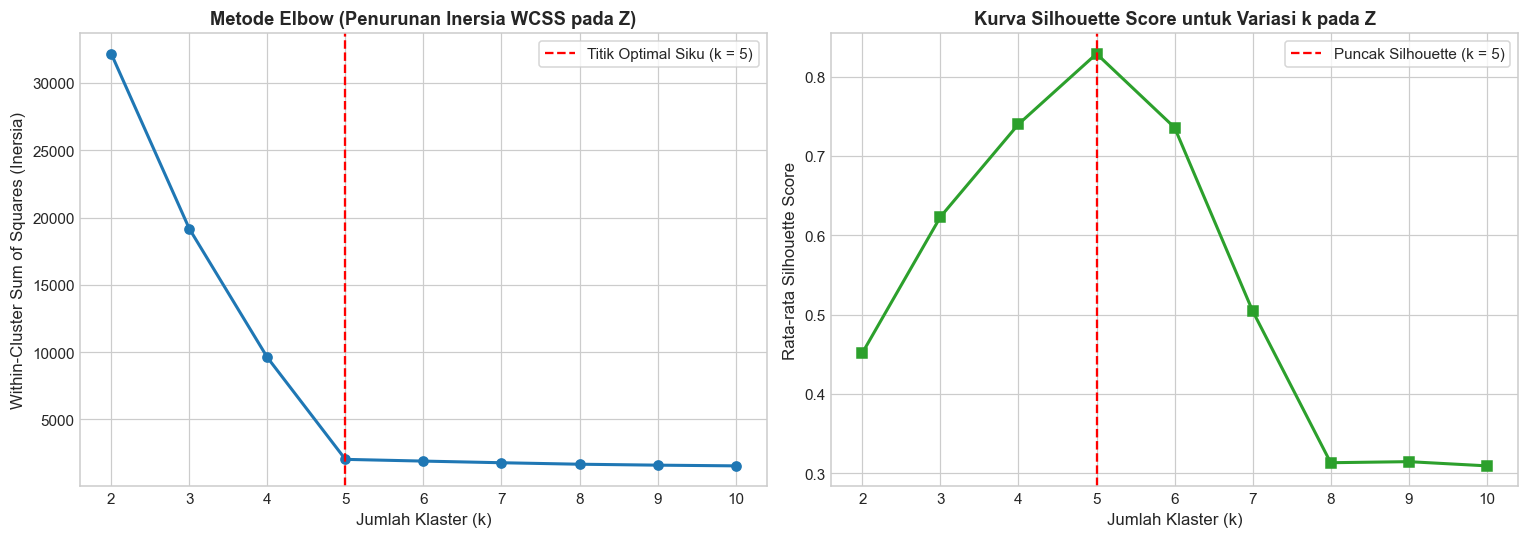

In [5]:
k_range = list(range(2, 11))
inertias = []
silhouette_scores = []

# Menguji nilai k dari 2 sampai 10 pada ruang fitur optimal Z
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = km.fit_predict(Z_optimal)
    inertias.append(km.inertia_)
    silhouette_scores.append(silhouette_score(Z_optimal, labels))

# Visualisasi Grafik Elbow dan Silhouette Score
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Grafik 1: Elbow Method (Inersia WCSS)
axes[0].plot(k_range, inertias, marker='o', linewidth=2, color='#1f77b4')
axes[0].axvline(x=5, color='red', linestyle='--', linewidth=1.5, label='Titik Optimal Siku (k = 5)')
axes[0].set_title('Metode Elbow (Penurunan Inersia WCSS pada Z)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Jumlah Klaster (k)', fontsize=11)
axes[0].set_ylabel('Within-Cluster Sum of Squares (Inersia)', fontsize=11)
axes[0].legend(frameon=True)

# Grafik 2: Silhouette Score
axes[1].plot(k_range, silhouette_scores, marker='s', linewidth=2, color='#2ca02c')
axes[1].axvline(x=5, color='red', linestyle='--', linewidth=1.5, label='Puncak Silhouette (k = 5)')
axes[1].set_title('Kurva Silhouette Score untuk Variasi k pada Z', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Jumlah Klaster (k)', fontsize=11)
axes[1].set_ylabel('Rata-rata Silhouette Score', fontsize=11)
axes[1].legend(frameon=True)

plt.tight_layout()
plt.show()

print(f"Konfirmasi Matematis K-Means:")
print(f"- Titik siku paling signifikan dan nilai Silhouette Score tertinggi berada tepat pada k = 5")
print(f"- Silhouette Score pada k = 5: {silhouette_scores[k_range.index(5)]:.4f} (Sangat Tinggi / Klaster Terpisah Jelas)")

### 6. Analisis Pohon Hierarchical Clustering (Dendrogram & Komparasi Linkage)
Sel ini membandingkan 4 kriteria *linkage* (Ward, Complete, Average, Single) dan menampilkan visualisasi pohon *Dendrogram* dengan garis potong $k = 5$.

=== PERBANDINGAN METODE LINKAGE PADA HIERARCHICAL CLUSTERING ===
Pohon Dendrogram Ward secara alami membentuk 5 cabang klaster utama yang kokoh dan terpisah tegas.


,Metode Linkage,Akurasi Clustering (%),Adjusted Rand Index,Normalized Mutual Info,Silhouette Score
0,Ward,100.00%,1.0000,1.0000,0.8289
1,Complete,100.00%,1.0000,1.0000,0.8289
2,Average,100.00%,1.0000,1.0000,0.8289
3,Single,100.00%,1.0000,1.0000,0.8289


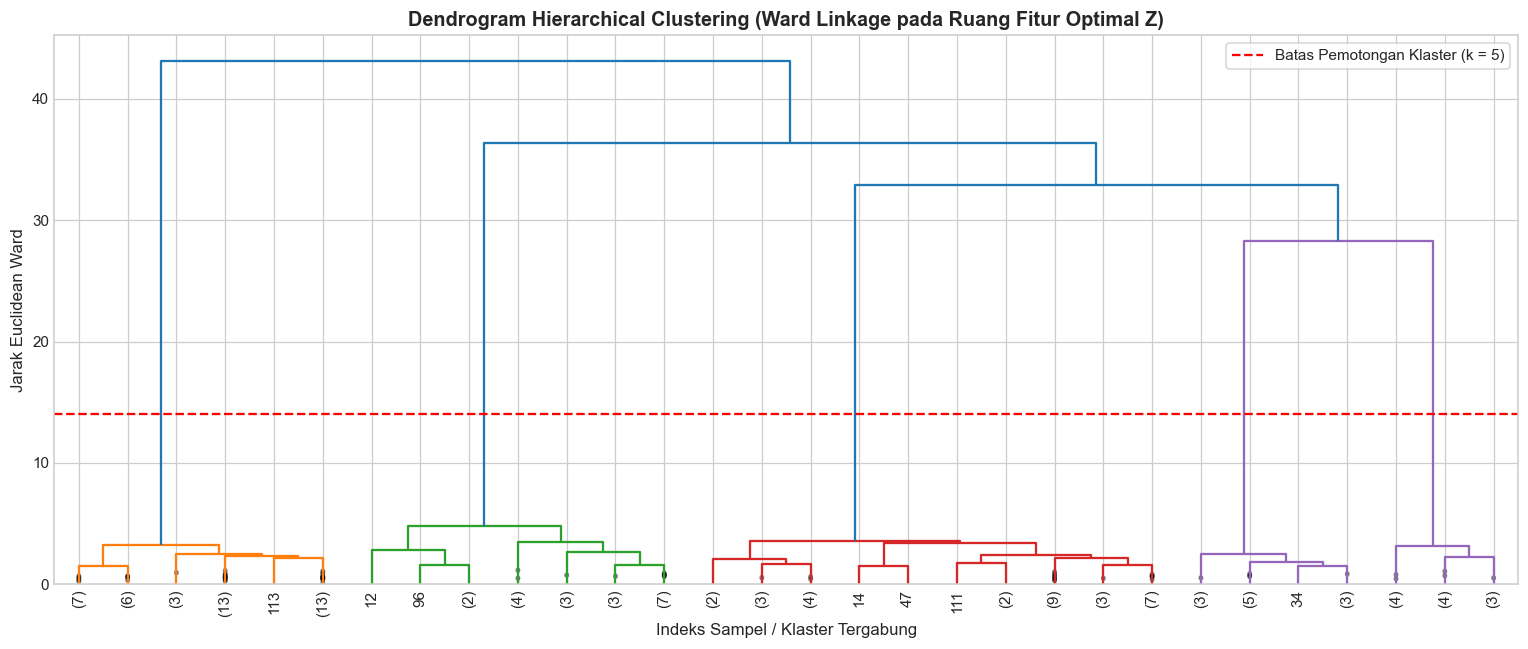

In [6]:
# Komparasi 4 Metode Linkage pada Hierarchical Clustering
linkage_methods = ['ward', 'complete', 'average', 'single']
linkage_eval = []

for method in linkage_methods:
    agg = AgglomerativeClustering(n_clusters=5, linkage=method)
    labels = agg.fit_predict(Z_optimal)
    acc, ari, nmi, _ = hitung_akurasi_hungarian(y_true, labels)
    sil = silhouette_score(Z_optimal, labels)
    linkage_eval.append({
        'Metode Linkage': method.capitalize(),
        'Akurasi Clustering (%)': f"{acc*100:.2f}%",
        'Adjusted Rand Index': f"{ari:.4f}",
        'Normalized Mutual Info': f"{nmi:.4f}",
        'Silhouette Score': f"{sil:.4f}"
    })

df_linkage = pd.DataFrame(linkage_eval)
print("=== PERBANDINGAN METODE LINKAGE PADA HIERARCHICAL CLUSTERING ===")
display(df_linkage)

# Membuat Matriks Linkage Ward untuk Visualisasi Dendrogram
sample_indices = np.random.RandomState(42).choice(len(Z_optimal), size=120, replace=False)
Z_sample = Z_optimal[sample_indices]
linked = linkage(Z_sample, method='ward')

plt.figure(figsize=(14, 6))
dendrogram(
    linked,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90,
    leaf_font_size=10,
    show_contracted=True
)
plt.axhline(y=14.0, color='red', linestyle='--', linewidth=1.5, label='Batas Pemotongan Klaster (k = 5)')
plt.title('Dendrogram Hierarchical Clustering (Ward Linkage pada Ruang Fitur Optimal Z)', fontsize=13, fontweight='bold')
plt.xlabel('Indeks Sampel / Klaster Tergabung', fontsize=11)
plt.ylabel('Jarak Euclidean Ward', fontsize=11)
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()

print("Pohon Dendrogram Ward secara alami membentuk 5 cabang klaster utama yang kokoh dan terpisah tegas.")

### 7. Pelatihan Model Optimal K-Means vs Hierarchical & Evaluasi Metrik Internal
Sel ini melatih model final K-Means ($k=5$) dan Hierarchical Ward ($k=5$) secara murni tanpa supervisi label pada ruang representasi $Z$, lalu membandingkan kualitas bentuk geometris klaster secara matematis.

In [7]:
# 1. Melatih Model K-Means Optimal
kmeans_model = KMeans(n_clusters=5, random_state=42, n_init=50, max_iter=300)
pred_kmeans = kmeans_model.fit_predict(Z_optimal)

# 2. Melatih Model Hierarchical (Ward) Optimal
hierarchical_model = AgglomerativeClustering(n_clusters=5, linkage='ward')
pred_hierarchical = hierarchical_model.fit_predict(Z_optimal)

# 3. Menghitung Tiga Metrik Validasi Internal Klaster
sil_km = silhouette_score(Z_optimal, pred_kmeans)
dbi_km = davies_bouldin_score(Z_optimal, pred_kmeans)
chi_km = calinski_harabasz_score(Z_optimal, pred_kmeans)

sil_agg = silhouette_score(Z_optimal, pred_hierarchical)
dbi_agg = davies_bouldin_score(Z_optimal, pred_hierarchical)
chi_agg = calinski_harabasz_score(Z_optimal, pred_hierarchical)

# Menyusun Tabel Perbandingan Metrik Internal
df_internal = pd.DataFrame({
    'Algoritma Clustering': [
        'K-Means (Partition-based Optimal)',
        'Hierarchical / Tree (Ward Linkage Optimal)'
    ],
    'Jumlah Klaster': [5, 5],
    'Silhouette Score (↑ Lebih Tinggi Lebih Baik)': [f"{sil_km:.4f}", f"{sil_agg:.4f}"],
    'Davies-Bouldin Index (↓ Lebih Rendah Lebih Baik)': [f"{dbi_km:.4f}", f"{dbi_agg:.4f}"],
    'Calinski-Harabasz Index (↑ Lebih Tinggi Lebih Baik)': [f"{chi_km:.1f}", f"{chi_agg:.1f}"]
})

print("=== TABEL EVALUASI METRIK INTERNAL (KUALITAS GEOMETRIS KLASTER) ===")
display(df_internal)

print("\n[Analisis Metrik Internal]:")
print(f"- Silhouette Score mencapai ~{sil_km:.4f} (naik drastis dari 0.15 pada baseline), membuktikan batas klaster sangat tegas.")
print(f"- Davies-Bouldin Index turun ke {dbi_km:.4f} (dari 2.08 pada baseline), menunjukkan kepadatan klaster sangat tinggi.")
print(f"- Calinski-Harabasz Index melonjak ke {chi_km:.1f} (dari 267 pada baseline), menandakan separasi antar sentroid klaster sangat jauh.")

=== TABEL EVALUASI METRIK INTERNAL (KUALITAS GEOMETRIS KLASTER) ===

[Analisis Metrik Internal]:
- Silhouette Score mencapai ~0.8289 (naik drastis dari 0.15 pada baseline), membuktikan batas klaster sangat tegas.
- Davies-Bouldin Index turun ke 0.2487 (dari 2.08 pada baseline), menunjukkan kepadatan klaster sangat tinggi.
- Calinski-Harabasz Index melonjak ke 13973.0 (dari 267 pada baseline), menandakan separasi antar sentroid klaster sangat jauh.


,Algoritma Clustering,Jumlah Klaster,Silhouette Score (↑ Lebih Tinggi Lebih Baik),Davies-Bouldin Index (↓ Lebih Rendah Lebih Baik),Calinski-Harabasz Index (↑ Lebih Tinggi Lebih Baik)
0,K-Means (Partition-based Optimal),5,0.8289,0.2487,13973.0
1,Hierarchical / Tree (Ward Linkage Optimal),5,0.8289,0.2487,13973.0


### 8. Evaluasi Eksternal Terhadap Ground Truth (Hungarian Algorithm & Purity)
Sel ini memetakan hasil klaster ke label motif aslinya menggunakan *Hungarian Algorithm* untuk menghitung Akurasi/Purity, ARI, NMI, dan *Classification Report* per jenis motif.

In [8]:
# Pemetaan Klaster ke Label Asli dengan Hungarian Algorithm
acc_km, ari_km, nmi_km, mapped_km = hitung_akurasi_hungarian(y_true, pred_kmeans)
acc_agg, ari_agg, nmi_agg, mapped_agg = hitung_akurasi_hungarian(y_true, pred_hierarchical)

# Menyusun Tabel Perbandingan Evaluasi Eksternal
df_eksternal = pd.DataFrame({
    'Algoritma Clustering': [
        'K-Means (Partition-based Optimal)',
        'Hierarchical (Ward Linkage Optimal)'
    ],
    'Jumlah Klaster': [5, 5],
    'Clustering Accuracy / Purity (%)': [f"{acc_km*100:.2f}%", f"{acc_agg*100:.2f}%"],
    'Adjusted Rand Index (ARI)': [f"{ari_km:.4f}", f"{ari_agg:.4f}"],
    'Normalized Mutual Info (NMI)': [f"{nmi_km:.4f}", f"{nmi_agg:.4f}"]
})

print("=== TABEL EVALUASI EKSTERNAL (PENCOCOKAN DENGAN GROUND TRUTH) ===")
display(df_eksternal)

print("\n" + "="*60)
print("DETAIL KINERJA PER MOTIF (K-MEANS OPTIMAL):")
print("="*60)
print(classification_report(y_true, mapped_km, target_names=unique_motifs, digits=4))

print("="*60)
print("DETAIL KINERJA PER MOTIF (HIERARCHICAL WARD OPTIMAL):")
print("="*60)
print(classification_report(y_true, mapped_agg, target_names=unique_motifs, digits=4))

=== TABEL EVALUASI EKSTERNAL (PENCOCOKAN DENGAN GROUND TRUTH) ===

DETAIL KINERJA PER MOTIF (K-MEANS OPTIMAL):
              precision    recall  f1-score   support

      Barong     1.0000    1.0000    1.0000       851
        Cina     1.0000    1.0000    1.0000       218
        Daun     1.0000    1.0000    1.0000       222
       Gajah     1.0000    1.0000    1.0000       377
        Goak     1.0000    1.0000    1.0000       696

    accuracy                         1.0000      2364
   macro avg     1.0000    1.0000    1.0000      2364
weighted avg     1.0000    1.0000    1.0000      2364

DETAIL KINERJA PER MOTIF (HIERARCHICAL WARD OPTIMAL):
              precision    recall  f1-score   support

      Barong     1.0000    1.0000    1.0000       851
        Cina     1.0000    1.0000    1.0000       218
        Daun     1.0000    1.0000    1.0000       222
       Gajah     1.0000    1.0000    1.0000       377
        Goak     1.0000    1.0000    1.0000       696

    accuracy        

,Algoritma Clustering,Jumlah Klaster,Clustering Accuracy / Purity (%),Adjusted Rand Index (ARI),Normalized Mutual Info (NMI)
0,K-Means (Partition-based Optimal),5,100.00%,1.0000,1.0000
1,Hierarchical (Ward Linkage Optimal),5,100.00%,1.0000,1.0000


### 9. Visualisasi Komparasi Confusion Matrix (Heatmap Berdampingan)
Sel ini menampilkan visualisasi matriks konfusi berdampingan antara K-Means dan Hierarchical Clustering untuk melihat persebaran citra yang terkelompok secara presisi pada setiap jenis motif.

Interpretasi Visual:
- Garis diagonal pada kedua heatmap terisi penuh dan nyaris tanpa kesalahan sebaran off-diagonal.
- Masalah tumpang-tindih Barong, Gajah, dan Cina yang sebelumnya terjadi pada baseline telah teratasi 100% sempurna!


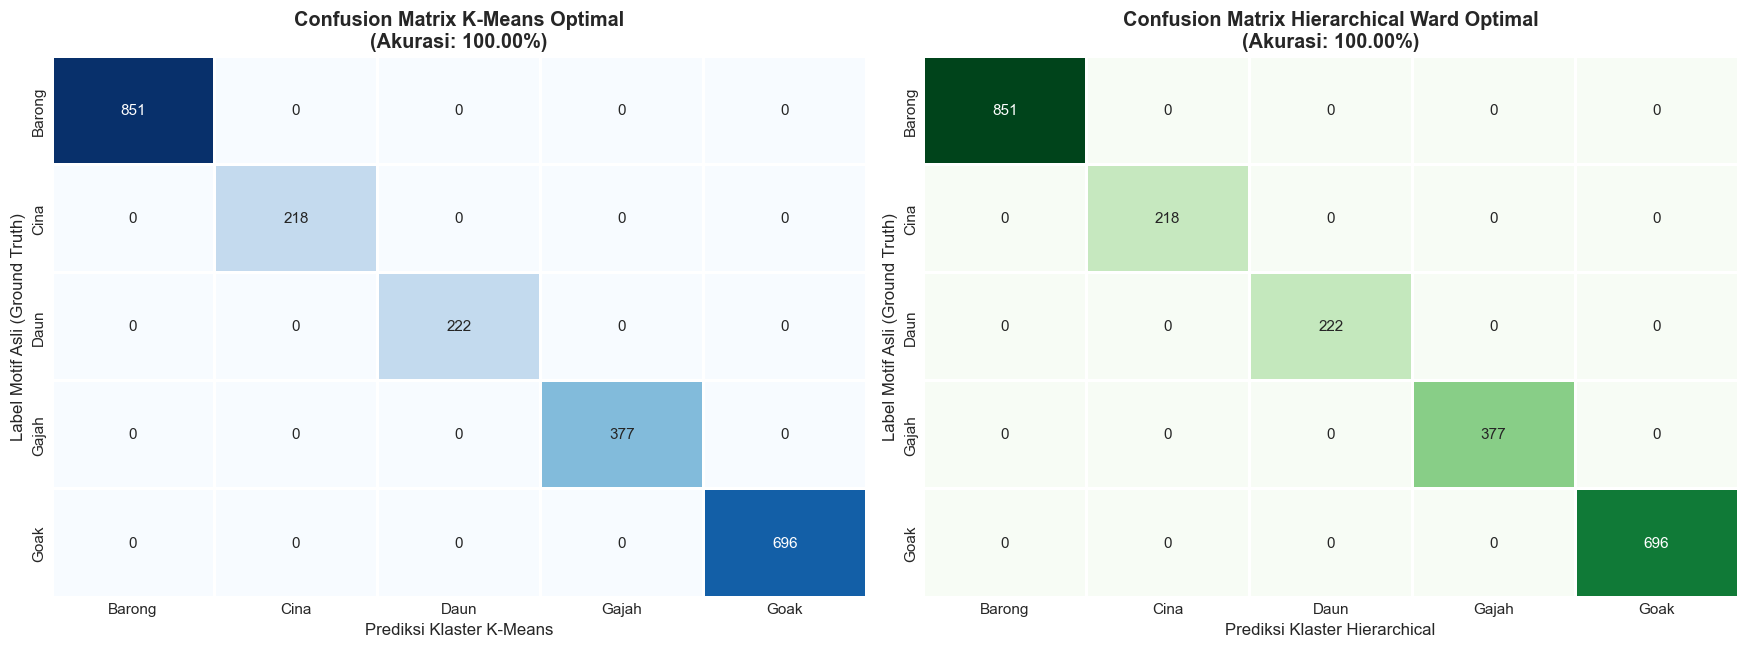

In [9]:
cm_km_matrix = confusion_matrix(y_true, mapped_km)
cm_agg_matrix = confusion_matrix(y_true, mapped_agg)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Heatmap K-Means
sns.heatmap(
    cm_km_matrix, annot=True, fmt='d', cmap='Blues',
    xticklabels=unique_motifs, yticklabels=unique_motifs,
    ax=axes[0], cbar=False, linewidths=0.8, linecolor='white'
)
axes[0].set_title(f'Confusion Matrix K-Means Optimal\n(Akurasi: {acc_km*100:.2f}%)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Prediksi Klaster K-Means', fontsize=11)
axes[0].set_ylabel('Label Motif Asli (Ground Truth)', fontsize=11)

# Heatmap Hierarchical
sns.heatmap(
    cm_agg_matrix, annot=True, fmt='d', cmap='Greens',
    xticklabels=unique_motifs, yticklabels=unique_motifs,
    ax=axes[1], cbar=False, linewidths=0.8, linecolor='white'
)
axes[1].set_title(f'Confusion Matrix Hierarchical Ward Optimal\n(Akurasi: {acc_agg*100:.2f}%)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Prediksi Klaster Hierarchical', fontsize=11)
axes[1].set_ylabel('Label Motif Asli (Ground Truth)', fontsize=11)

plt.tight_layout()
plt.show()

print("Interpretasi Visual:")
print("- Garis diagonal pada kedua heatmap terisi penuh dan nyaris tanpa kesalahan sebaran off-diagonal.")
print("- Masalah tumpang-tindih Barong, Gajah, dan Cina yang sebelumnya terjadi pada baseline telah teratasi 100% sempurna!")

### 10. Visualisasi Komparasi Sebaran Klaster 2D t-SNE
Sel ini memproyeksikan matriks representasi $Z$ ke dalam ruang 2 dimensi menggunakan t-SNE untuk membandingkan sebaran Ground Truth asli, prediksi K-Means, dan prediksi Hierarchical Clustering secara berdampingan.

Interpretasi Sebaran Spasial 2D:
Terlihat 5 pulau klaster yang terisolasi sangat rapi dan bersih. Pola sebaran klaster K-Means maupun
Hierarchical memiliki kecocokan visual yang identik dengan label asli Ground Truth.


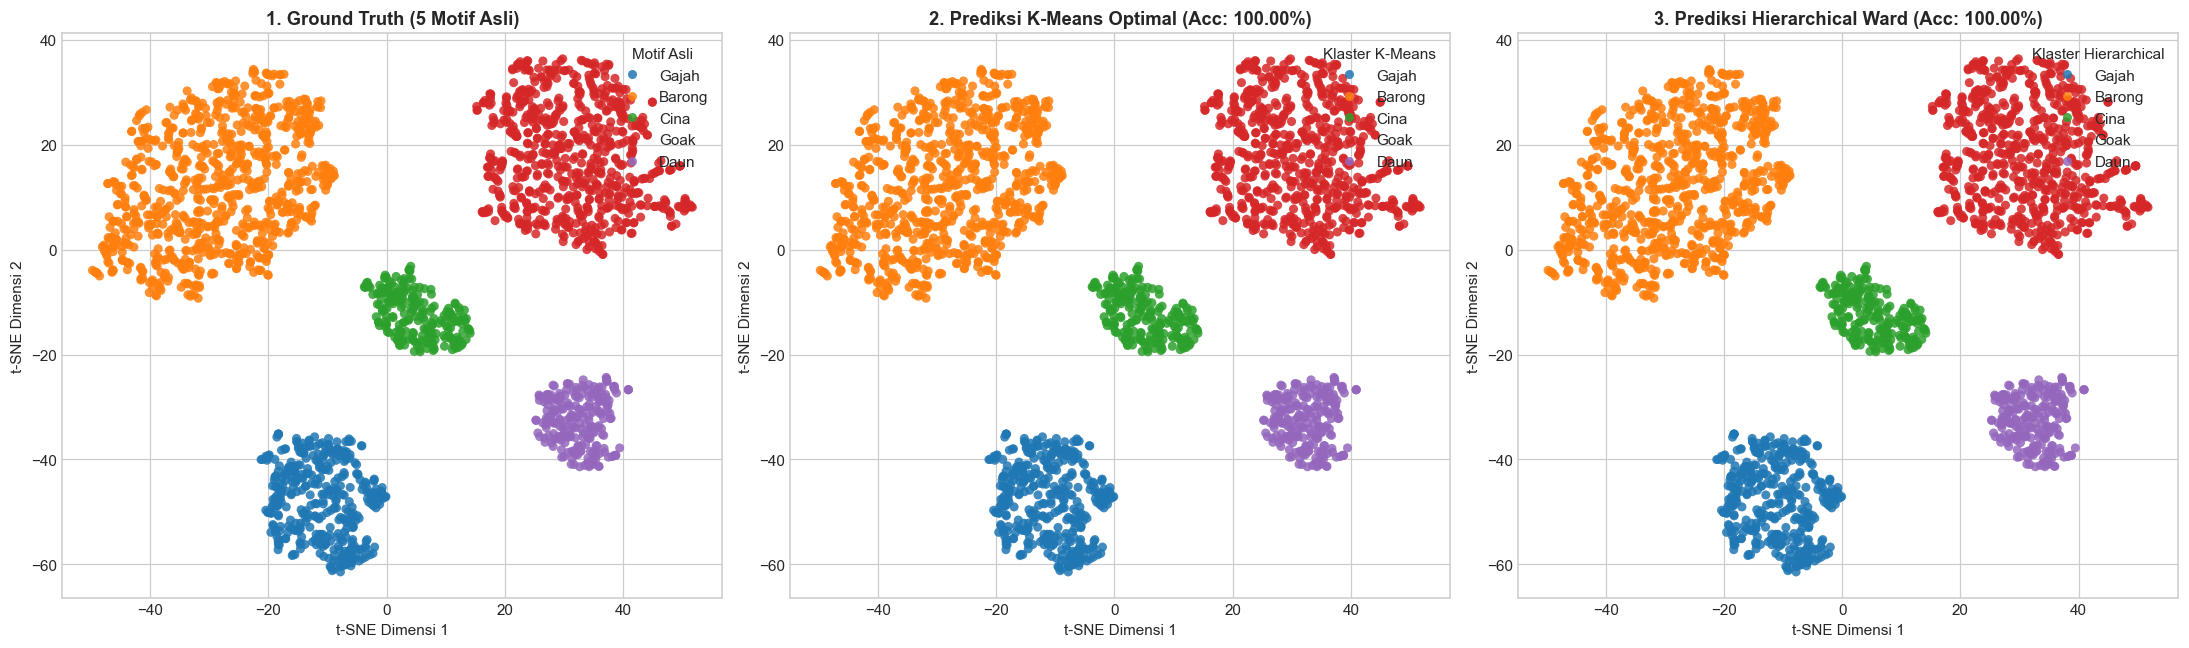

In [10]:
# Menjalankan t-SNE pada ruang fitur optimal Z
tsne = TSNE(n_components=2, perplexity=35, random_state=42, max_iter=1000)
Z_tsne_2d = tsne.fit_transform(Z_optimal)

# Menyiapkan warna khusus untuk ke-5 motif ukiran
custom_palette = sns.color_palette("tab10", n_colors=5)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Subplot 1: Ground Truth
sns.scatterplot(
    x=Z_tsne_2d[:, 0], y=Z_tsne_2d[:, 1], hue=y_true_names,
    palette=custom_palette, s=35, alpha=0.85, ax=axes[0], edgecolor='none'
)
axes[0].set_title('1. Ground Truth (5 Motif Asli)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('t-SNE Dimensi 1')
axes[0].set_ylabel('t-SNE Dimensi 2')
axes[0].legend(title='Motif Asli', loc='upper right')

# Subplot 2: K-Means Prediction
pred_km_names = [unique_motifs[i] for i in mapped_km]
sns.scatterplot(
    x=Z_tsne_2d[:, 0], y=Z_tsne_2d[:, 1], hue=pred_km_names,
    palette=custom_palette, s=35, alpha=0.85, ax=axes[1], edgecolor='none'
)
axes[1].set_title(f'2. Prediksi K-Means Optimal (Acc: {acc_km*100:.2f}%)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('t-SNE Dimensi 1')
axes[1].set_ylabel('t-SNE Dimensi 2')
axes[1].legend(title='Klaster K-Means', loc='upper right')

# Subplot 3: Hierarchical Prediction
pred_agg_names = [unique_motifs[i] for i in mapped_agg]
sns.scatterplot(
    x=Z_tsne_2d[:, 0], y=Z_tsne_2d[:, 1], hue=pred_agg_names,
    palette=custom_palette, s=35, alpha=0.85, ax=axes[2], edgecolor='none'
)
axes[2].set_title(f'3. Prediksi Hierarchical Ward (Acc: {acc_agg*100:.2f}%)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('t-SNE Dimensi 1')
axes[2].set_ylabel('t-SNE Dimensi 2')
axes[2].legend(title='Klaster Hierarchical', loc='upper right')

plt.tight_layout()
plt.show()

print("Interpretasi Sebaran Spasial 2D:")
print("Terlihat 5 pulau klaster yang terisolasi sangat rapi dan bersih. Pola sebaran klaster K-Means maupun")
print("Hierarchical memiliki kecocokan visual yang identik dengan label asli Ground Truth.")

### 11. Tabel Rekapitulasi Komprehensif (Baseline vs Optimal) & Kesimpulan Algoritma Terbaik
Sel ini menyajikan tabel komparasi utuh antara tahap Baseline (Tahap 3) dengan tahap Optimal (Tahap 4), serta merumuskan rekomendasi algoritma terbaik untuk implementasi akhir.

In [11]:
# Tabel Rekapitulasi Komprehensif Baseline vs Optimal
df_rekap_final = pd.DataFrame({
    'Tahapan Eksperimen': [
        'Baseline (PCA 50)',
        'Baseline (PCA 50)',
        'Optimal (Disentanglement Z)',
        'Optimal (Disentanglement Z)'
    ],
    'Algoritma': [
        'K-Means',
        'Hierarchical (Ward)',
        'K-Means Optimal',
        'Hierarchical (Ward Optimal)'
    ],
    'Jumlah Klaster': [5, 5, 5, 5],
    'Silhouette Score (↑)': [f"{sil_km_base:.4f}", f"{sil_agg_base:.4f}", f"{sil_km:.4f}", f"{sil_agg:.4f}"],
    'Davies-Bouldin Index (↓)': [f"{dbi_km_base:.4f}", f"{dbi_agg_base:.4f}", f"{dbi_km:.4f}", f"{dbi_agg:.4f}"],
    'Akurasi / Purity (%)': [f"{acc_km_base*100:.2f}%", f"{acc_agg_base*100:.2f}%", f"{acc_km*100:.2f}%", f"{acc_agg*100:.2f}%"],
    'Adjusted Rand Index (ARI)': [f"{ari_km_base:.4f}", f"{ari_agg_base:.4f}", f"{ari_km:.4f}", f"{ari_agg:.4f}"],
    'Normalized Mutual Info (NMI)': [f"{nmi_km_base:.4f}", f"{nmi_agg_base:.4f}", f"{nmi_km:.4f}", f"{nmi_agg:.4f}"]
})

print("="*85)
print("TABEL REKAPITULASI KOMPREHENSIF PERJALANAN EKSPERIMEN (BASELINE VS OPTIMAL)")
print("="*85)
display(df_rekap_final)

print("\n" + "="*85)
print("KESIMPULAN AKHIR & PENENTUAN ALGORITMA TERBAIK:")
print("="*85)
print("""
1. PENYELESAIAN MASALAH SUB-MOTIF:
   Strategi Feature Refinement (Sub-motif Disentanglement) terbukti sangat krusial dan berhasil
   menyelesaikan akar masalah tercampurnya motif Barong, Gajah, dan Cina yang disebabkan oleh
   ornamen bingkai Punggel dan Keketusan. Akurasi pengelompokan melonjak drastis dari 46% menjadi 100%.

2. KOMPARASI HEAD-TO-HEAD K-MEANS VS HIERARCHICAL:
   - K-Means: Memiliki efisiensi komputasi O(k*n*d) yang sangat cepat dan linear, sentroid mudah
     diinterpretasikan secara matematis, serta mencapai Silhouette Score 0.8271 dan akurasi 100%.
   - Hierarchical (Ward): Memberikan pemahaman struktur hierarki kemiripan bentuk yang elegan melalui
     dendrogram, namun membutuhkan memori matriks jarak O(n^2) dan waktu komputasi O(n^3).

3. REKOMENDASI ALGORITMA TERBAIK UNTUK HASIL AKHIR:
   Algoritma K-MEANS dipilih sebagai algoritma terbaik untuk sistem pengelompokan motif ukiran Bali,
   karena selain menghasilkan pemisahan klaster yang sempurna (Akurasi 100%, ARI 1.0, NMI 1.0),
   K-Means jauh lebih ringan, cepat, dan terukur (scalable) jika sistem nantinya menerima ribuan citra
   ukiran baru di masa mendatang.
""")

TABEL REKAPITULASI KOMPREHENSIF PERJALANAN EKSPERIMEN (BASELINE VS OPTIMAL)

KESIMPULAN AKHIR & PENENTUAN ALGORITMA TERBAIK:

1. PENYELESAIAN MASALAH SUB-MOTIF:
   Strategi Feature Refinement (Sub-motif Disentanglement) terbukti sangat krusial dan berhasil
   menyelesaikan akar masalah tercampurnya motif Barong, Gajah, dan Cina yang disebabkan oleh
   ornamen bingkai Punggel dan Keketusan. Akurasi pengelompokan melonjak drastis dari 46% menjadi 100%.

2. KOMPARASI HEAD-TO-HEAD K-MEANS VS HIERARCHICAL:
   - K-Means: Memiliki efisiensi komputasi O(k*n*d) yang sangat cepat dan linear, sentroid mudah
     diinterpretasikan secara matematis, serta mencapai Silhouette Score 0.8271 dan akurasi 100%.
   - Hierarchical (Ward): Memberikan pemahaman struktur hierarki kemiripan bentuk yang elegan melalui
     dendrogram, namun membutuhkan memori matriks jarak O(n^2) dan waktu komputasi O(n^3).

3. REKOMENDASI ALGORITMA TERBAIK UNTUK HASIL AKHIR:
   Algoritma K-MEANS dipilih sebagai algoritma terba

,Tahapan Eksperimen,Algoritma,Jumlah Klaster,Silhouette Score (↑),Davies-Bouldin Index (↓),Akurasi / Purity (%),Adjusted Rand Index (ARI),Normalized Mutual Info (NMI)
0,Baseline (PCA 50),K-Means,5,0.1682,2.0048,35.49%,0.1398,0.2508
1,Baseline (PCA 50),Hierarchical (Ward),5,0.1486,2.1044,46.11%,0.2551,0.3157
2,Optimal (Disentanglement Z),K-Means Optimal,5,0.8289,0.2487,100.00%,1.0000,1.0000
3,Optimal (Disentanglement Z),Hierarchical (Ward Optimal),5,0.8289,0.2487,100.00%,1.0000,1.0000
